# ANÁLISE SAML-D

In [2]:
import pandas as pd 
import numpy as np 
import matplotlib as mtl 
import seaborn as sns 
import matplotlib.pyplot as plt

# Análise Inicial
- Número de linhas e colunas
- O significado de cada coluna
- Identificar o tipo de dado de cada coluna
- Investigar valores ausentes e duplicados
- Verificar se as contas estão sendo representadas como números ou identificadores
- Investigar se **Date** e **Time** estão armazenados em texto
- Descobrir quantas moedas, localizações e modalidades de pagamento existem

In [3]:
dataset = pd.read_csv('SAML-D.csv')

In [4]:
dataset.head()

,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type
0,10:35:19,2022-10-07,8724731955,2769355426,1459.15,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits
1,10:35:20,2022-10-07,1491989064,8401255335,6019.64,UK pounds,Dirham,UK,UAE,Cross-border,0,Normal_Fan_Out
2,10:35:20,2022-10-07,287305149,4404767002,14328.44,UK pounds,UK pounds,UK,UK,Cheque,0,Normal_Small_Fan_Out
3,10:35:21,2022-10-07,5376652437,9600420220,11895.00,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Fan_In
4,10:35:21,2022-10-07,9614186178,3803336972,115.25,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits


In [5]:
dataset.tail()

,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type
9504847,10:57:01,2023-08-23,2453933570,519744068,2247.25,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Small_Fan_Out
9504848,10:57:06,2023-08-23,9805510177,5416607878,927.18,UK pounds,UK pounds,UK,UK,Debit card,0,Normal_Small_Fan_Out
9504849,10:57:06,2023-08-23,7282330957,2995527149,1455.14,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Small_Fan_Out
9504850,10:57:11,2023-08-23,940337377,4812815165,25995.70,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Fan_In
9504851,10:57:12,2023-08-23,105185176,6824994831,9586.08,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Fan_Out


##### Colunas
- Time: horário da transação
- Date: data da transação
- Sender_account: conta remetente
- Receiver_account: conta destinatária
- Amount: valor da transação
- Payment_currency: moeda de pagamento
- Received_currency: moeda recebida
- Sender_bank_location: localização bancária do remetente
- Receiver_bank_location: localização bancária do destinatário
- Payment_type: tipo de pagamento
- Is_laundering: indicador de lavagem de dinheiro
- Laundering_type: Tipo de comportamento identificado


In [7]:
dataset.columns

Index(['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount',
       'Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type', 'Is_laundering',
       'Laundering_type'],
      dtype='str')

In [8]:
dataset.dtypes

Time                          str
Date                          str
Sender_account              int64
Receiver_account            int64
Amount                    float64
Payment_currency              str
Received_currency             str
Sender_bank_location          str
Receiver_bank_location        str
Payment_type                  str
Is_laundering               int64
Laundering_type               str
dtype: object

### Estatísticas

In [24]:
dataset.describe()

,Sender_account,Receiver_account,Amount,Is_laundering
count,9.504852e+06,9.504852e+06,9.504852e+06,9.504852e+06
mean,5.006619e+09,5.006006e+09,8.762968e+03,1.038733e-03
std,2.885814e+09,2.884763e+09,2.561495e+04,3.221263e-02
min,9.018000e+03,9.018000e+03,3.730000e+00,0.000000e+00
25%,2.513133e+09,2.513219e+09,2.143688e+03,0.000000e+00
50%,5.001017e+09,5.002572e+09,6.113720e+03,0.000000e+00
75%,7.505051e+09,7.502397e+09,1.045846e+04,0.000000e+00
max,9.999987e+09,9.999971e+09,1.261850e+07,1.000000e+00


In [18]:
def dataset_statistics(dataset):
    colunas_numericas = dataset.select_dtypes(include="number").columns

    for coluna in colunas_numericas:
        print(f"\n=== ESTATÍSTICAS: {coluna.upper()} ===")
        print(f"Média: {dataset[coluna].mean():.4f}")
        print(f"Mediana: {dataset[coluna].median():.4f}")
        print(f"Desvio padrão: {dataset[coluna].std():.4f}")
        print(f"Maior valor: {dataset[coluna].max():.2f}")
        print(f"Menor valor: {dataset[coluna].min():.2f}")
        print(f"Quantidade: {dataset[coluna].count()}")

In [19]:
dataset_statistics(dataset)


=== ESTATÍSTICAS: SENDER_ACCOUNT ===
Média: 5006619409.9689
Mediana: 5001016667.0000
Desvio padrão: 2885813892.1314
Maior valor: 9999986843.00
Menor valor: 9018.00
Quantidade: 9504852

=== ESTATÍSTICAS: RECEIVER_ACCOUNT ===
Média: 5006006469.6481
Mediana: 5002572491.5000
Desvio padrão: 2884762983.2694
Maior valor: 9999971095.00
Menor valor: 9018.00
Quantidade: 9504852

=== ESTATÍSTICAS: AMOUNT ===
Média: 8762.9676
Mediana: 6113.7200
Desvio padrão: 25614.9530
Maior valor: 12618498.40
Menor valor: 3.73
Quantidade: 9504852

=== ESTATÍSTICAS: IS_LAUNDERING ===
Média: 0.0010
Mediana: 0.0000
Desvio padrão: 0.0322
Maior valor: 1.00
Menor valor: 0.00
Quantidade: 9504852


In [22]:
print("Dimensões:", dataset.shape)
print("Amostras aleatórias: ")
display(dataset.sample(min(5, len(dataset)), random_state=42))

Dimensões: (9504852, 12)
Amostras aleatórias: 


,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type
42444,19:24:09,2022-10-08,6077900993,6609117934,2299.89,UK pounds,UK pounds,UK,UK,Debit card,0,Normal_Group
8169290,18:12:15,2023-07-08,5459041199,816242179,211.90,UK pounds,UK pounds,UK,UK,Cheque,0,Normal_Small_Fan_Out
7894834,12:19:54,2023-06-29,4641798002,5214523833,9481.26,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Fan_In
4265755,11:35:53,2023-02-27,1475899462,6151077027,11609.92,UK pounds,UK pounds,UK,UK,Debit card,0,Normal_Fan_Out
7437932,10:54:00,2023-06-14,8046287266,3423799664,17772.58,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Fan_In


### Verificação de Valores Nulos

In [25]:
display(dataset.isna().sum().sort_values(ascending=False))

Time                      0
Date                      0
Sender_account            0
Receiver_account          0
Amount                    0
Payment_currency          0
Received_currency         0
Sender_bank_location      0
Receiver_bank_location    0
Payment_type              0
Is_laundering             0
Laundering_type           0
dtype: int64

### Verificação de Valores Duplicados

In [3]:
print("Registros duplicados:", dataset.duplicated().sum())

Registros duplicados: 0


### Valores Monetários

In [3]:
print("=== VALORES DE QUANTIA ===")
print("Mínimo: ", dataset["Amount"].min())
print("Máximo: ", dataset["Amount"].max())
print("Valores iguais a zero: ", (dataset["Amount"] == 0).sum())
print("Valores negativos: ", (dataset["Amount"] < 0).sum())
print("Valores infinitos: ", np.isinf(dataset["Amount"].sum()))

=== VALORES DE QUANTIA ===
Mínimo:  3.73
Máximo:  12618498.4
Valores iguais a zero:  0
Valores negativos:  0
Valores infinitos:  False


### Rótulos da Variável-Alvo
9873 registros suspeitos de lavagem de dinheiro.

In [4]:
print("\nValores de Is_laundering:")
print(dataset["Is_laundering"].value_counts(dropna=False))


Valores de Is_laundering:
Is_laundering
0    9494979
1       9873
Name: count, dtype: int64


### Categorias das Colunas Textuais

In [5]:
colunas_categoricas = [
    "Payment_currency",
    "Received_currency",
    "Sender_bank_location",
    "Receiver_bank_location",
    "Payment_type"
]

for coluna in colunas_categoricas:
    print(f"\n{coluna}:")
    print("Quantidade de categorias:", dataset[coluna].nunique())
    print(dataset[coluna].value_counts(dropna=False).head(15))


Payment_currency:
Quantidade de categorias: 13
Payment_currency
UK pounds          9099293
Euro                117164
Turkish lira         27996
Swiss franc          27492
Dirham               27263
Pakistani rupee      27196
Naira                27143
US dollar            26061
Yen                  25562
Moroccan dirham      25395
Mexican Peso         24852
Albanian lek         24778
Indian rupee         24657
Name: count, dtype: int64

Received_currency:
Quantidade de categorias: 13
Received_currency
UK pounds          8783655
Euro                231911
Pakistani rupee      45993
Yen                  45814
Moroccan dirham      45748
Albanian lek         45736
Mexican Peso         45255
Naira                45046
Indian rupee         43757
US dollar            43664
Swiss franc          42931
Dirham               42797
Turkish lira         42545
Name: count, dtype: int64

Sender_bank_location:
Quantidade de categorias: 18
Sender_bank_location
UK             9183088
Turkey           2

## Gráficos

### Distribuição das Classes
- Não identificada como lavagem de dinheiro: 99,896127% 
- Identificada como lavagem de dinheiro: 0,103873%

O rótulo não é uma garantia de lavagem de dinheiro, apesar de ser útil para treinar e avaliar o classificador.

Is_laundering
Não identificada como lavagem    9494979
Identificada como lavagem           9873
Name: count, dtype: int64

Is_laundering
0    99.896127
1     0.103873
Name: Percentual, dtype: float64

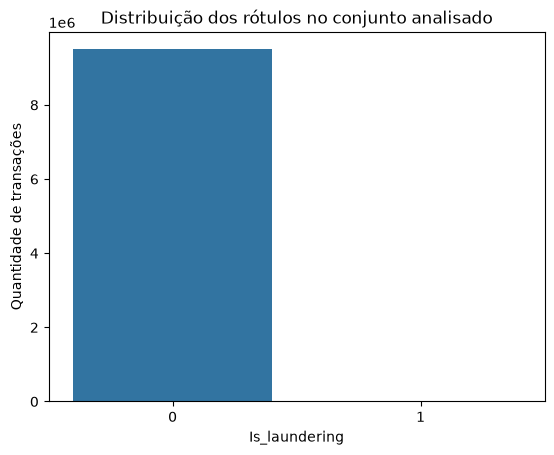

In [9]:
contagem = dataset["Is_laundering"].value_counts().sort_index()

display(contagem.rename(index={
    0: "Não identificada como lavagem",
    1: "Identificada como lavagem"
}))

display(
    (dataset["Is_laundering"].value_counts(normalize=True) * 100)
    .rename("Percentual")
)

sns.countplot(data=dataset, x="Is_laundering")
plt.title("Distribuição dos rótulos no conjunto analisado")
plt.xlabel("Is_laundering")
plt.ylabel("Quantidade de transações")
plt.show()


### Valores das Transações
Valores altos **podem** indicar uma métrica útil para identificar se uma transação é lavagem de dinheiro, mas **não é uma garantia**.

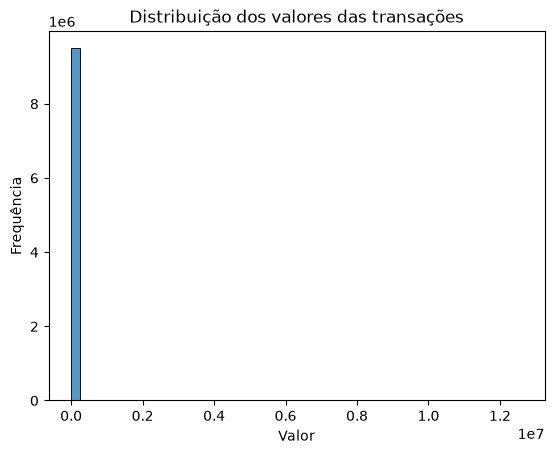

In [10]:
sns.histplot(data=dataset, x="Amount", bins=50)
plt.title("Distribuição dos valores das transações")
plt.xlabel("Valor")
plt.ylabel("Frequência")
plt.show()

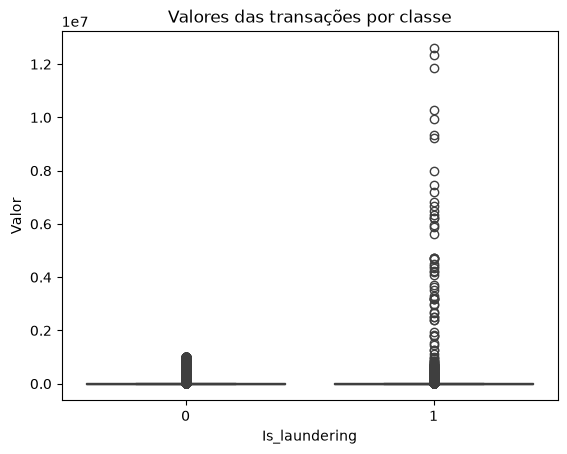

In [11]:
sns.boxplot(data=dataset, x="Is_laundering", y="Amount")
plt.title("Valores das transações por classe")
plt.xlabel("Is_laundering")
plt.ylabel("Valor")
plt.show()


In [ ]:
resumo_valores = (
    dataset.groupby("Is_laundering")["Amount"]
    .agg(["count", "mean", "median", "min", "max"])
)

display(resumo_valores)


,count,mean,median,min,max
Is_laundering,,,,,
0,9494979,8729.875874,6114.63,3.73,999962.19
1,9873,40587.666906,5322.79,15.82,12618498.40


In [14]:
percentis = (
    dataset.groupby("Is_laundering")["Amount"]
    .quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .unstack()
)

percentis.columns = [
    "P25", "P50 (mediana)", "P75", "P90", "P95", "P99"
]

display(percentis)

,P25,P50 (mediana),P75,P90,P95,P99
Is_laundering,,,,,,
0,2142.93,6114.63,10458.950000,16558.43,22031.332000,44938.1608
1,2723.79,5322.79,9789.673317,21197.62,39698.428296,419540.0832


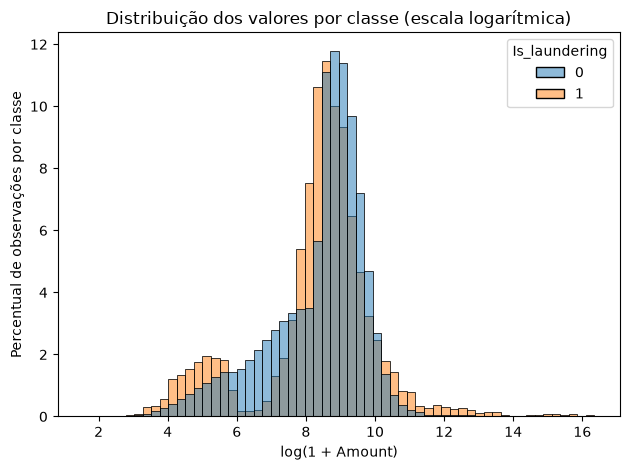

In [15]:
dataset["Amount_log"] = np.log1p(dataset["Amount"])

sns.histplot(
    data=dataset,
    x="Amount_log",
    hue="Is_laundering",
    bins=60,
    stat="percent",
    common_norm=False
)

plt.title("Distribuição dos valores por classe (escala logarítmica)")
plt.xlabel("log(1 + Amount)")
plt.ylabel("Percentual de observações por classe")
plt.tight_layout()
plt.show()

### Tipo de Pagamento x Quantidade

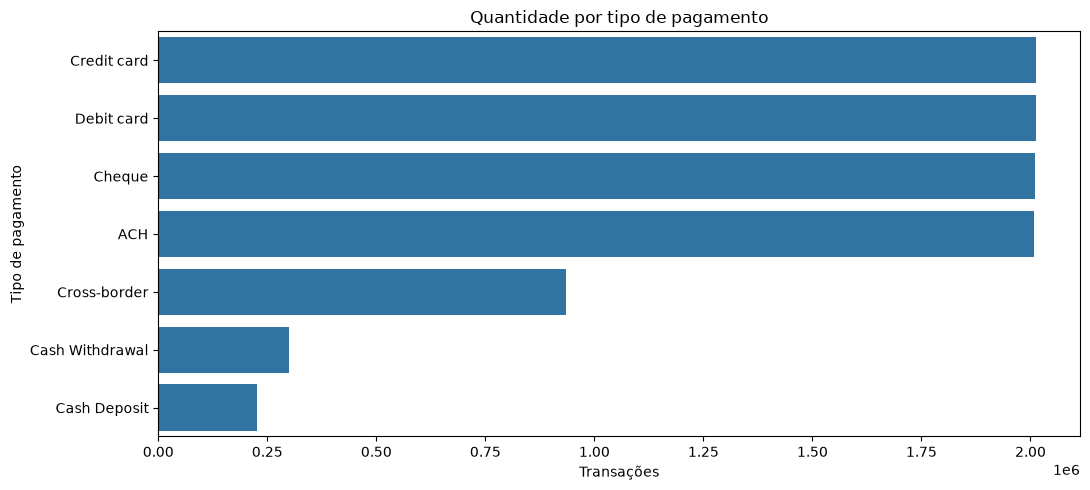

In [8]:
plt.figure(figsize=(11, 5))

sns.countplot(
    data=dataset,
    y="Payment_type",
    order=dataset["Payment_type"].value_counts().index
)

plt.title("Quantidade por tipo de pagamento")
plt.xlabel("Transações")
plt.ylabel("Tipo de pagamento")
plt.tight_layout()
plt.show()


### Transações Positivas de Cada Categoria
Uma transação positiva indica que uma transação é classificada como lavagem de dinheiro.
- Cash Deposit: 1405
- Cash Withdrawal: 1334
- Cross-border: 2628
- ACH: 1159
- Credit card: 1136
- Debit card: 1124
- Cheque: 1087

In [12]:
taxa_por_pagamento = (
    dataset.groupby("Payment_type")["Is_laundering"]
      .agg(["count", "sum", "mean"])
      .sort_values("mean", ascending=False)
)

taxa_por_pagamento["taxa_percentual"] = (
    taxa_por_pagamento["mean"] * 100
)

display(taxa_por_pagamento)


,count,sum,mean,taxa_percentual
Payment_type,,,,
Cash Deposit,225206,1405,0.006239,0.623873
Cash Withdrawal,300477,1334,0.004440,0.443961
Cross-border,933931,2628,0.002814,0.281391
ACH,2008807,1159,0.000577,0.057696
Credit card,2012909,1136,0.000564,0.056436
Debit card,2012103,1124,0.000559,0.055862
Cheque,2011419,1087,0.000540,0.054041


#### Quantas categorias existem?

In [16]:
print(dataset["Payment_type"].value_counts())

Payment_type
Credit card        2012909
Debit card         2012103
Cheque             2011419
ACH                2008807
Cross-border        933931
Cash Withdrawal     300477
Cash Deposit        225206
Name: count, dtype: int64


#### Quantas transações positivas há em cada categoria?

In [17]:
positivas = dataset[dataset["Is_laundering"] == 1]

print(positivas["Payment_type"].value_counts())

Payment_type
Cross-border       2628
Cash Deposit       1405
Cash Withdrawal    1334
ACH                1159
Credit card        1136
Debit card         1124
Cheque             1087
Name: count, dtype: int64


In [18]:
for coluna in [
    "Payment_type",
    "Payment_currency",
    "Received_currency",
    "Sender_bank_location",
    "Receiver_bank_location"
]:
    print(f"\n=== {coluna} ===")

    resultado = (
        dataset.groupby(coluna)["Is_laundering"]
        .agg(total="count", positivas="sum", taxa_positiva="mean")
    )

    resultado["taxa_positiva"] *= 100
    display(resultado.sort_values("taxa_positiva", ascending=False))


=== Payment_type ===


,total,positivas,taxa_positiva
Payment_type,,,
Cash Deposit,225206,1405,0.623873
Cash Withdrawal,300477,1334,0.443961
Cross-border,933931,2628,0.281391
ACH,2008807,1159,0.057696
Credit card,2012909,1136,0.056436
Debit card,2012103,1124,0.055862
Cheque,2011419,1087,0.054041



=== Payment_currency ===


,total,positivas,taxa_positiva
Payment_currency,,,
Moroccan dirham,25395,90,0.354400
Dirham,27263,89,0.326450
Swiss franc,27492,82,0.298269
Indian rupee,24657,68,0.275784
Mexican Peso,24852,68,0.273620
Turkish lira,27996,73,0.260752
Albanian lek,24778,64,0.258294
Yen,25562,65,0.254284
US dollar,26061,60,0.230229



=== Received_currency ===


,total,positivas,taxa_positiva
Received_currency,,,
Naira,45046,288,0.639346
Moroccan dirham,45748,285,0.622978
Albanian lek,45736,262,0.572853
Dirham,42797,225,0.525738
Mexican Peso,45255,235,0.519280
Turkish lira,42545,218,0.512399
Pakistani rupee,45993,204,0.443546
Indian rupee,43757,172,0.393080
Euro,231911,716,0.308739



=== Sender_bank_location ===


,total,positivas,taxa_positiva
Sender_bank_location,,,
Morocco,18437,55,0.298313
Mexico,17662,44,0.249122
Netherlands,16770,41,0.244484
India,17596,42,0.238691
Italy,18895,45,0.238158
Germany,19259,43,0.223272
Austria,18050,38,0.210526
Japan,18468,38,0.205761
Switzerland,20503,41,0.199971



=== Receiver_bank_location ===


,total,positivas,taxa_positiva
Receiver_bank_location,,,
Nigeria,38272,251,0.655832
Morocco,38704,253,0.653679
Albania,38783,235,0.605936
UAE,35897,195,0.543221
Mexico,38385,197,0.513221
Turkey,35586,177,0.497387
Pakistan,38980,169,0.433556
Netherlands,37314,148,0.396634
Austria,38844,154,0.396458


# Comportamento das Classes
- Sender_account: conta remetente
- quantidades_envios: quantas transações esssa conta enviou
- valor_total_enviado: soma de todos os valores enviados pela conta
- valor_medio_enviado: valor total / quantidade de transações
- quantidades_destinatarios: número de contas destinatárias que o remetente enviou o dinheiro

In [6]:
envios = (
    dataset.groupby("Sender_account")
      .agg(
          quantidade_envios=("Amount", "size"),
          valor_total_enviado=("Amount", "sum"),
          valor_medio_enviado=("Amount", "mean"),
          quantidade_destinatarios=("Receiver_account", "nunique")
      )
      .sort_values("quantidade_envios", ascending=False)
)

display(envios.head(20))


,quantidade_envios,valor_total_enviado,valor_medio_enviado,quantidade_destinatarios
Sender_account,,,,
4808614002,754,4450195.04,5902.115438,25
2938210715,753,4052721.72,5382.100558,23
5579295130,751,4570856.24,6086.359840,25
3831533348,749,5210276.12,6956.309907,55
2357599526,749,5688771.44,7595.155461,25
798082205,743,5053281.51,6801.186420,58
9810335545,742,3908506.89,5267.529501,23
8600542721,738,2123264.63,2877.052344,25
8913863501,736,3140740.94,4267.311060,24


#### Quem aparece mais vezes como destinatário?

In [7]:
recebimentos = (
    dataset.groupby("Receiver_account")
    .agg(
        quantidade_recebimentos=("Amount", "size"),
        valor_total_recebido=("Amount", "sum"),
        valor_medio_recebido=("Amount", "mean"),
        quantidade_remetentes=("Sender_account", "nunique")
    )
    .sort_values("quantidade_recebimentos", ascending=False)
)

display(recebimentos.head(20))

,quantidade_recebimentos,valor_total_recebido,valor_medio_recebido,quantidade_remetentes
Receiver_account,,,,
8600542721,751,4182791.24,5569.628815,17
2938210715,745,4997841.44,6708.512000,17
5460360634,740,4141297.11,5596.347446,17
5579295130,739,3363836.68,4551.876428,17
4808614002,737,2943969.44,3994.531126,17
4724445469,736,5258861.76,7145.192609,17
3747015869,734,3092588.99,4213.336499,17
9544431251,734,4836645.33,6589.435054,17
4924631375,734,2766504.27,3769.079387,17


#### Quais pares de contas mais transacionam?

In [8]:
pares_contas = (
    dataset.groupby(["Sender_account", "Receiver_account"])
    .agg(
        quantidade_transacoes=("Amount", "size"),
        valor_total=("Amount", "sum"),
        valor_medio=("Amount", "mean")
    )
    .sort_values("quantidade_transacoes", ascending=False)
)

display(pares_contas.head(20))

,,quantidade_transacoes,valor_total,valor_medio
Sender_account,Receiver_account,,,
5032745881,5216531044,84,145334.72,1730.175238
1931246840,2078538423,84,881735.42,10496.850238
1337920692,3232244126,83,172745.21,2081.267590
7234973076,6408343900,83,546764.21,6587.520602
8117397180,3922554569,83,449601.29,5416.883012
6369359732,5216531044,82,107531.97,1311.365488
5992045283,2766094282,82,76652.71,934.789146
7641911870,2086374242,82,169922.13,2072.221098
417590431,4290035884,82,167165.46,2038.603171


### Taxas de Transações Suspeitas por Categorias

#### Transações Suspeitas por Modalidade

In [4]:
def analisar_categoria(dataset, coluna, alvo="Is_laundering"):
    resumo = (
        dataset.groupby(coluna, dropna=False)[alvo]
        .agg(
            total="count",
            suspeitas="sum",
            taxa_suspeita="mean"
        )
        .sort_values("taxa_suspeita", ascending=False)
    )

    resumo["taxa_suspeita_pct"] = (
        resumo["taxa_suspeita"] * 100
    )

    return resumo

resumo_pagamento = analisar_categoria(
    dataset,
    "Payment_type"
)

display(resumo_pagamento)

,total,suspeitas,taxa_suspeita,taxa_suspeita_pct
Payment_type,,,,
Cash Deposit,225206,1405,0.006239,0.623873
Cash Withdrawal,300477,1334,0.004440,0.443961
Cross-border,933931,2628,0.002814,0.281391
ACH,2008807,1159,0.000577,0.057696
Credit card,2012909,1136,0.000564,0.056436
Debit card,2012103,1124,0.000559,0.055862
Cheque,2011419,1087,0.000540,0.054041


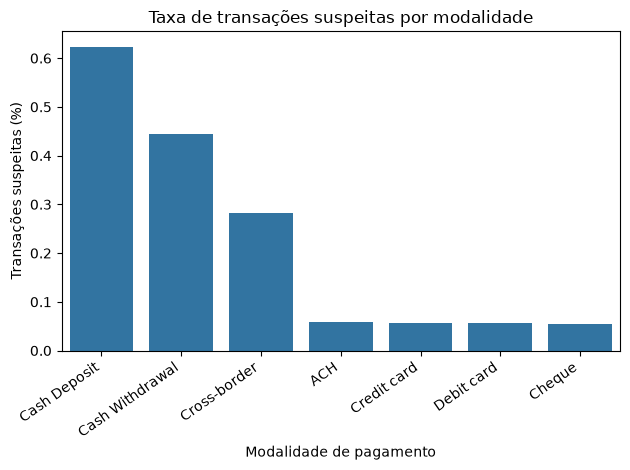

In [5]:
sns.barplot(
    data=resumo_pagamento.reset_index(),
    x="Payment_type",
    y="taxa_suspeita_pct"
)

plt.title("Taxa de transações suspeitas por modalidade")
plt.xlabel("Modalidade de pagamento")
plt.ylabel("Transações suspeitas (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

#### Transações Suspeitas por Moeda

In [6]:
resumo_pagamento = analisar_categoria(
    dataset,
    "Payment_currency"
)

display(resumo_pagamento)

,total,suspeitas,taxa_suspeita,taxa_suspeita_pct
Payment_currency,,,,
Moroccan dirham,25395,90,0.003544,0.354400
Dirham,27263,89,0.003264,0.326450
Swiss franc,27492,82,0.002983,0.298269
Indian rupee,24657,68,0.002758,0.275784
Mexican Peso,24852,68,0.002736,0.273620
Turkish lira,27996,73,0.002608,0.260752
Albanian lek,24778,64,0.002583,0.258294
Yen,25562,65,0.002543,0.254284
US dollar,26061,60,0.002302,0.230229


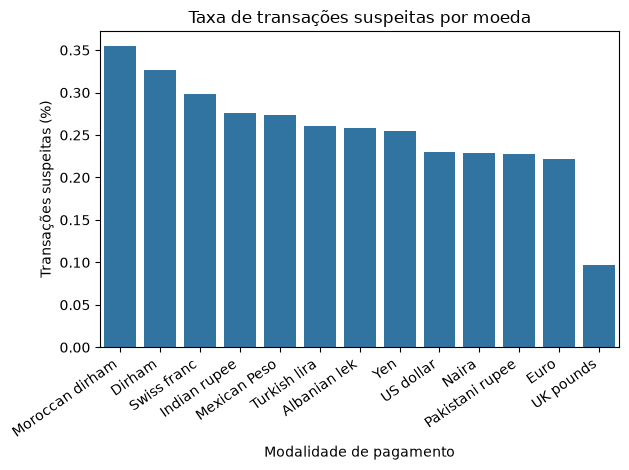

In [7]:
sns.barplot(
    data=resumo_pagamento.reset_index(),
    x="Payment_currency",
    y="taxa_suspeita_pct"
)

plt.title("Taxa de transações suspeitas por moeda")
plt.xlabel("Modalidade de pagamento")
plt.ylabel("Transações suspeitas (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

#### Transações Suspeitas por Localização do Remetente

In [8]:
resumo_pagamento = analisar_categoria(
    dataset,
    "Sender_bank_location"
)

display(resumo_pagamento)

,total,suspeitas,taxa_suspeita,taxa_suspeita_pct
Sender_bank_location,,,,
Morocco,18437,55,0.002983,0.298313
Mexico,17662,44,0.002491,0.249122
Netherlands,16770,41,0.002445,0.244484
India,17596,42,0.002387,0.238691
Italy,18895,45,0.002382,0.238158
Germany,19259,43,0.002233,0.223272
Austria,18050,38,0.002105,0.210526
Japan,18468,38,0.002058,0.205761
Switzerland,20503,41,0.002000,0.199971


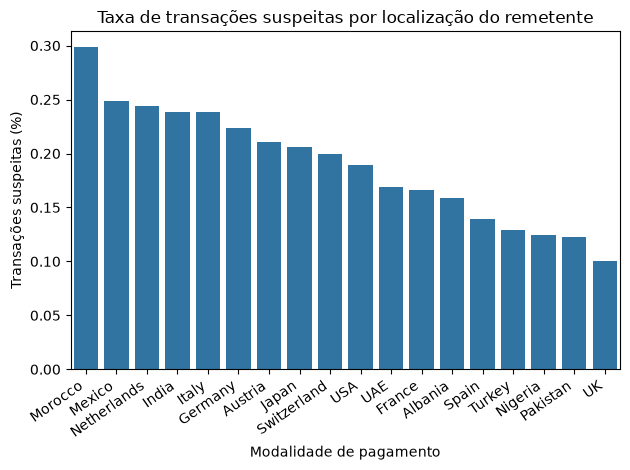

In [9]:
sns.barplot(
    data=resumo_pagamento.reset_index(),
    x="Sender_bank_location",
    y="taxa_suspeita_pct"
)

plt.title("Taxa de transações suspeitas por localização do remetente")
plt.xlabel("Modalidade de pagamento")
plt.ylabel("Transações suspeitas (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

#### Transações Suspeitas por Localização do Destinatário

In [10]:
resumo_pagamento = analisar_categoria(
    dataset,
    "Receiver_bank_location"
)

display(resumo_pagamento)

,total,suspeitas,taxa_suspeita,taxa_suspeita_pct
Receiver_bank_location,,,,
Nigeria,38272,251,0.006558,0.655832
Morocco,38704,253,0.006537,0.653679
Albania,38783,235,0.006059,0.605936
UAE,35897,195,0.005432,0.543221
Mexico,38385,197,0.005132,0.513221
Turkey,35586,177,0.004974,0.497387
Pakistan,38980,169,0.004336,0.433556
Netherlands,37314,148,0.003966,0.396634
Austria,38844,154,0.003965,0.396458


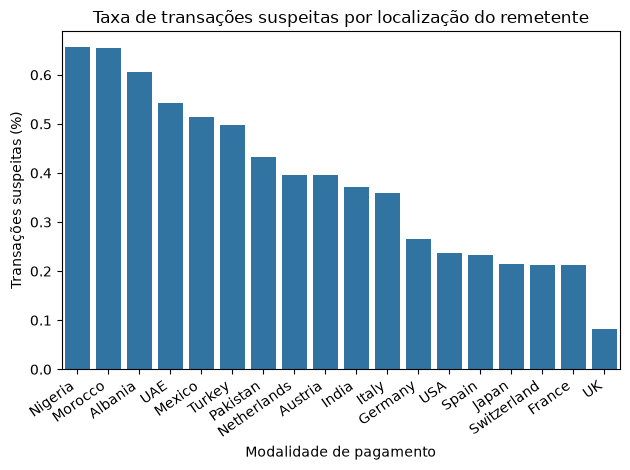

In [12]:
sns.barplot(
    data=resumo_pagamento.reset_index(),
    x="Receiver_bank_location",
    y="taxa_suspeita_pct"
)

plt.title("Taxa de transações suspeitas por localização do remetente")
plt.xlabel("Modalidade de pagamento")
plt.ylabel("Transações suspeitas (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### Comparação de Launderin_type com Is_laundering

In [13]:
tabela_tipologias = pd.crosstab(
    dataset["Laundering_type"],
    dataset["Is_laundering"],
    margins=True,
    margins_name="Total"
)

display(tabela_tipologias)

Is_laundering,0,1,Total
Laundering_type,,,
Behavioural_Change_1,0,394,394
Behavioural_Change_2,0,345,345
Bipartite,0,383,383
Cash_Withdrawal,0,1334,1334
Cycle,0,382,382
Deposit-Send,0,945,945
Fan_In,0,364,364
Fan_Out,0,237,237
Gather-Scatter,0,354,354


In [14]:
resumo_tipologias = analisar_categoria(
    dataset,
    "Laundering_type"
)

display(resumo_tipologias)

,total,suspeitas,taxa_suspeita,taxa_suspeita_pct
Laundering_type,,,,
Behavioural_Change_1,394,394,1.0,100.0
Behavioural_Change_2,345,345,1.0,100.0
Bipartite,383,383,1.0,100.0
Cash_Withdrawal,1334,1334,1.0,100.0
Cycle,382,382,1.0,100.0
Deposit-Send,945,945,1.0,100.0
Fan_In,364,364,1.0,100.0
Fan_Out,237,237,1.0,100.0
Gather-Scatter,354,354,1.0,100.0


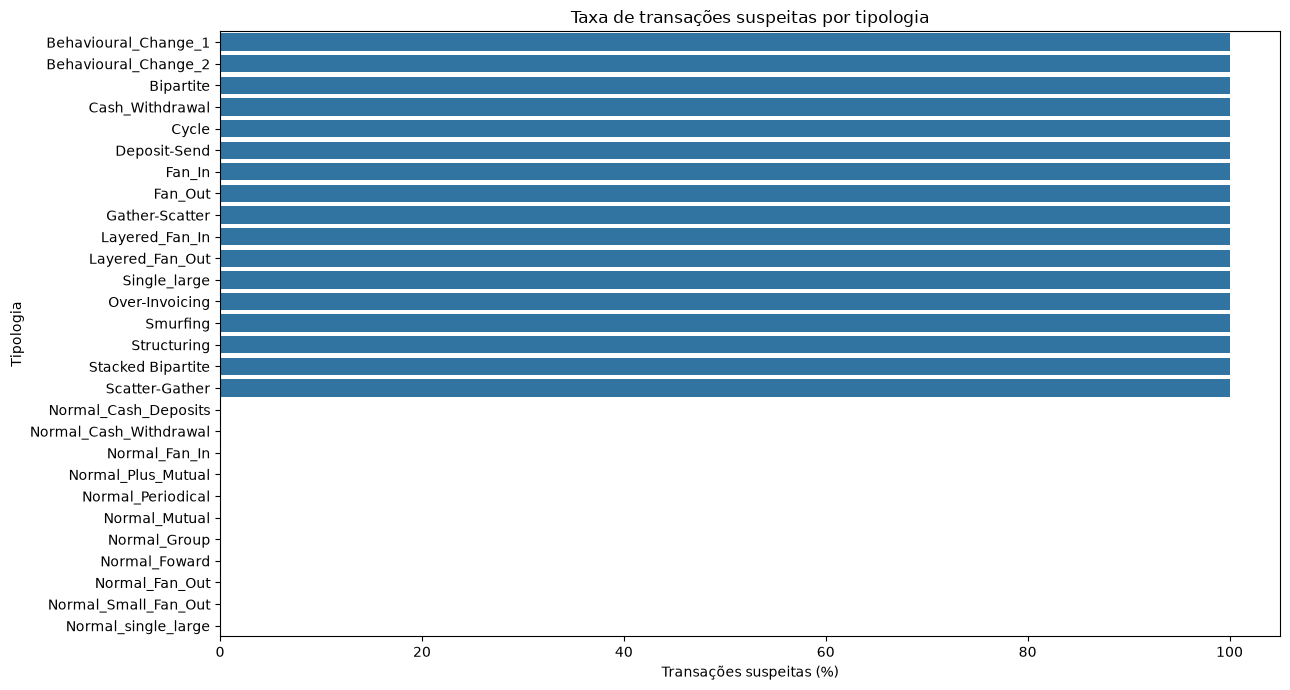

In [15]:
grafico_tipologias = (
    resumo_tipologias
    .reset_index()
    .sort_values("taxa_suspeita_pct", ascending=False)
)

plt.figure(figsize=(13, 7))

sns.barplot(
    data=grafico_tipologias,
    x="taxa_suspeita_pct",
    y="Laundering_type"
)

plt.title("Taxa de transações suspeitas por tipologia")
plt.xlabel("Transações suspeitas (%)")
plt.ylabel("Tipologia")
plt.tight_layout()
plt.show()

### Amount_log x Amount

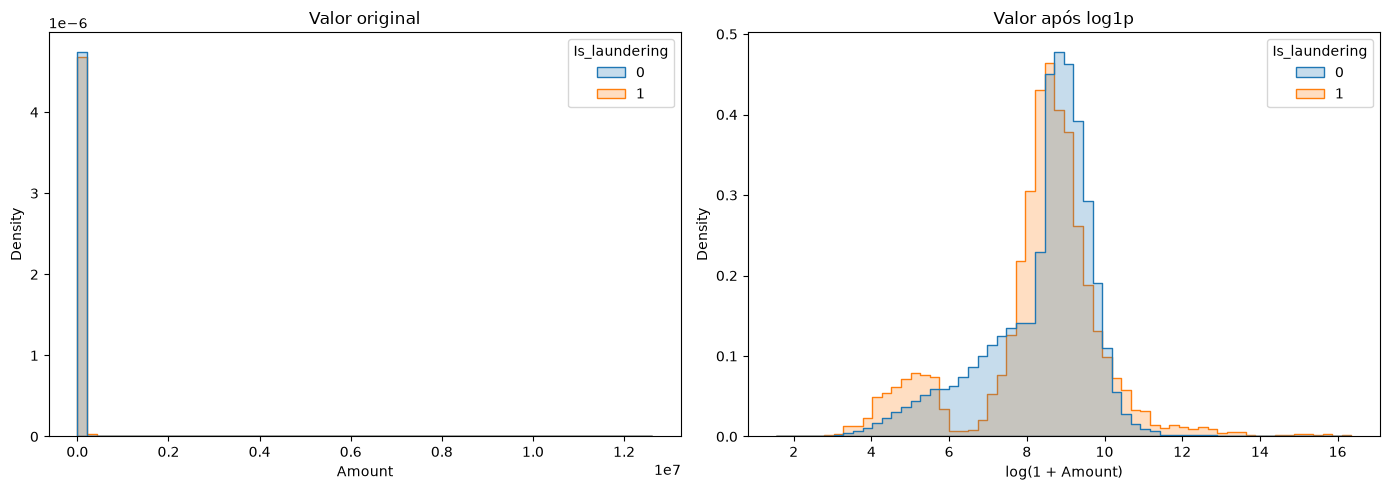

In [16]:
dataset["Amount_log"] = np.log1p(dataset["Amount"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=dataset,
    x="Amount",
    hue="Is_laundering",
    bins=60,
    element="step",
    stat="density",
    common_norm=False,
    ax=axes[0]
)

axes[0].set_title("Valor original")
axes[0].set_xlabel("Amount")

sns.histplot(
    data=dataset,
    x="Amount_log",
    hue="Is_laundering",
    bins=60,
    element="step",
    stat="density",
    common_norm=False,
    ax=axes[1]
)

axes[1].set_title("Valor após log1p")
axes[1].set_xlabel("log(1 + Amount)")

plt.tight_layout()
plt.show()